# Proyecto final: IA, redes sociales y bienestar estudiantil

## Metodología CRISP-DM — modelado y despliegue (5.1–5.10)

**Objetivo:** estimar `Mental_Health_Score` mediante regresión, a partir de características demográficas y hábitos registrados. El modelo es exploratorio: no es diagnóstico clínico ni demuestra causalidad.

**Fuente:** `AI_SocialMedia_Student_Dataset.xlsx`, hoja `Sheet1`, en esta carpeta o en la raíz del proyecto. No se proporcionó ficha técnica externa; las interpretaciones de unidades y puntajes se infieren de los nombres de las columnas.

**Entorno:** Python 3.10+ y `pandas`, `numpy`, `openpyxl`, `matplotlib`, `seaborn`, `scikit-learn`, `mlflow`. Si faltan, ejecute `%pip install pandas numpy openpyxl matplotlib seaborn scikit-learn mlflow` en el kernel y reinícielo. MLflow guarda el registro localmente en SQLite.

Semilla 42; partición entrenamiento/Test 80/20; validación cruzada de cinco pliegues solo en entrenamiento. Test se reserva para evaluación final.

## 5.1 Comprensión del contexto y de los datos

El dominio es el bienestar estudiantil en relación con edad, educación, uso diario de redes sociales y herramientas de IA, sueño, actividad física y puntajes de salud. Cada registro representa un estudiante. No se asume que los registros sean longitudinales ni representativos de una población: la procedencia, fecha de recolección y método de muestreo no están documentados.

El objetivo es predecir el puntaje numérico `Mental_Health_Score` y analizar el desempeño predictivo con las variables disponibles. La inferencia no debe emplearse como diagnóstico, recomendación clínica o conclusión causal.

### Diccionario de datos (interpretación operativa)

| Variable | Tipo | Significado inferido | Rol |
|---|---|---|---|
| `Student_ID` | Texto | Identificador del registro | Excluir de X |
| `Age` | Numérica discreta | Edad en años | Predictora |
| `Gender` | Categórica | Categoría de género registrada | Predictora |
| `Education_Level` | Categórica | Nivel educativo | Predictora |
| `Daily_Social_Media_Hours` | Numérica | Horas diarias en redes sociales | Predictora |
| `Daily_AI_Tool_Usage_Hours` | Numérica | Horas diarias de uso de IA | Predictora |
| `Sleep_Hours` | Numérica | Horas de sueño registradas | Predictora |
| `Physical_Activity_Hours` | Numérica | Horas de actividad física registradas | Predictora |
| `Mental_Health_Score` | Numérica continua | Puntaje de salud mental; escala formal desconocida | Objetivo |
| `Physical_Health_Score` | Numérica continua | Puntaje de salud física; escala formal desconocida | Predictora condicionada |

Las escalas, unidades y límites no documentados se tratan como desconocidos; se verifican rangos observados sin atribuirles significado clínico.

In [11]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
TARGET = "Mental_Health_Score"
DATA_FILENAME = "AI_SocialMedia_Student_Dataset.xlsx"
paths = [
    Path.cwd() / DATA_FILENAME,
    Path.cwd() / "03_Notebook" / DATA_FILENAME,
]
if "__file__" in globals():
    paths.insert(0, Path(__file__).parent / DATA_FILENAME)
DATA_PATH = next((p.resolve() for p in paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"No se encontró {DATA_FILENAME}; colóquelo junto al notebook "
        "o en 03_Notebook."
    )
df = pd.read_excel(DATA_PATH, sheet_name="Sheet1")
print(f"Archivo: {DATA_PATH}")
print(f"Hoja Sheet1 | Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())

Archivo: C:\Users\USER\Documents\PROYECTO _FINAL_MULTIVALUADO\03_Notebook\AI_SocialMedia_Student_Dataset.xlsx
Hoja Sheet1 | Dimensiones: 16,000 filas × 10 columnas


,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


## 5.2 Carga y exploración

Se carga explícitamente la hoja `Sheet1`. Se presentan dimensiones, primeras filas, tipos, estadísticas descriptivas, frecuencias y distribuciones de las variables antes de limpiar o transformar.

In [12]:
print("Tipos:")
display(df.dtypes.rename("tipo").to_frame())
print("Estadísticas numéricas:")
display(df.describe(include=[np.number]).T)
print("Resumen categórico:")
display(df.describe(include=["object", "string"]).T)

categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
for col in categorical_columns:
    print(f"\nFrecuencias de {col}:")
    display(df[col].value_counts(dropna=False).rename("conteo").to_frame())

Tipos:


,tipo
Student_ID,str
Age,int64
Gender,str
Education_Level,str
Daily_Social_Media_Hours,float64
Daily_AI_Tool_Usage_Hours,float64
Sleep_Hours,float64
Physical_Activity_Hours,float64
Mental_Health_Score,float64
Physical_Health_Score,float64


Estadísticas numéricas:


,count,mean,std,min,25%,50%,75%,max
Age,16000.0,19.038750,3.765270,13.00,16.0000,19.000,22.00,25.00
Daily_Social_Media_Hours,16000.0,4.541791,2.403044,0.00,2.8400,4.500,6.18,14.00
Daily_AI_Tool_Usage_Hours,16000.0,2.590624,1.679376,0.00,1.3100,2.520,3.75,9.50
Sleep_Hours,16000.0,6.545371,1.270515,2.00,5.6800,6.540,7.41,11.15
Physical_Activity_Hours,16000.0,1.248359,1.038632,0.00,0.3100,1.130,1.96,5.00
Mental_Health_Score,16000.0,72.493193,9.244818,32.56,66.7600,73.750,79.55,91.76
Physical_Health_Score,16000.0,88.020465,9.691037,48.03,81.5175,89.455,97.17,99.98


Resumen categórico:


,count,unique,top,freq
Student_ID,16000,16000,STU_00001,1
Gender,16000,3,Male,7744
Education_Level,16000,3,High School,6083


... (2 outputs left out)


Frecuencias de Gender:


,conteo
Gender,
Male,7744
Female,7628
Non-binary,628



Frecuencias de Education_Level:


,conteo
Education_Level,
High School,6083
University,5027
College,4890


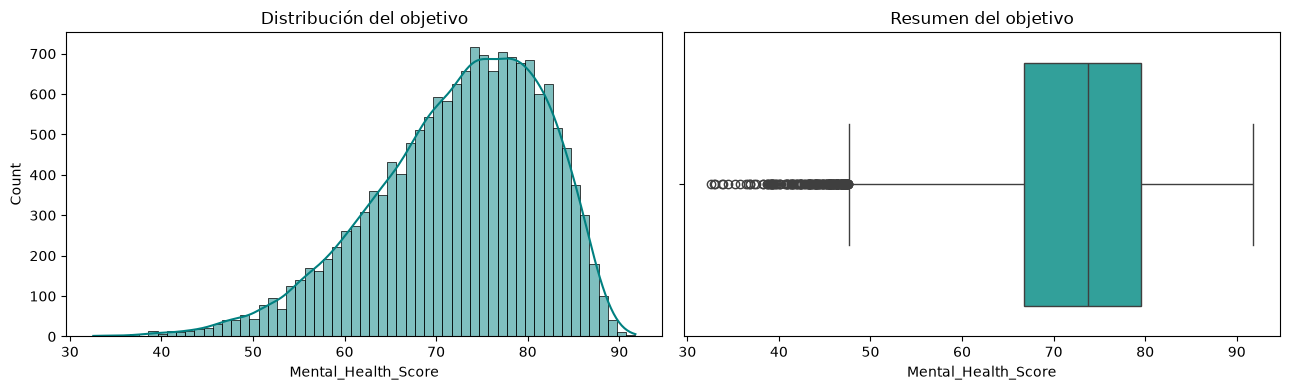

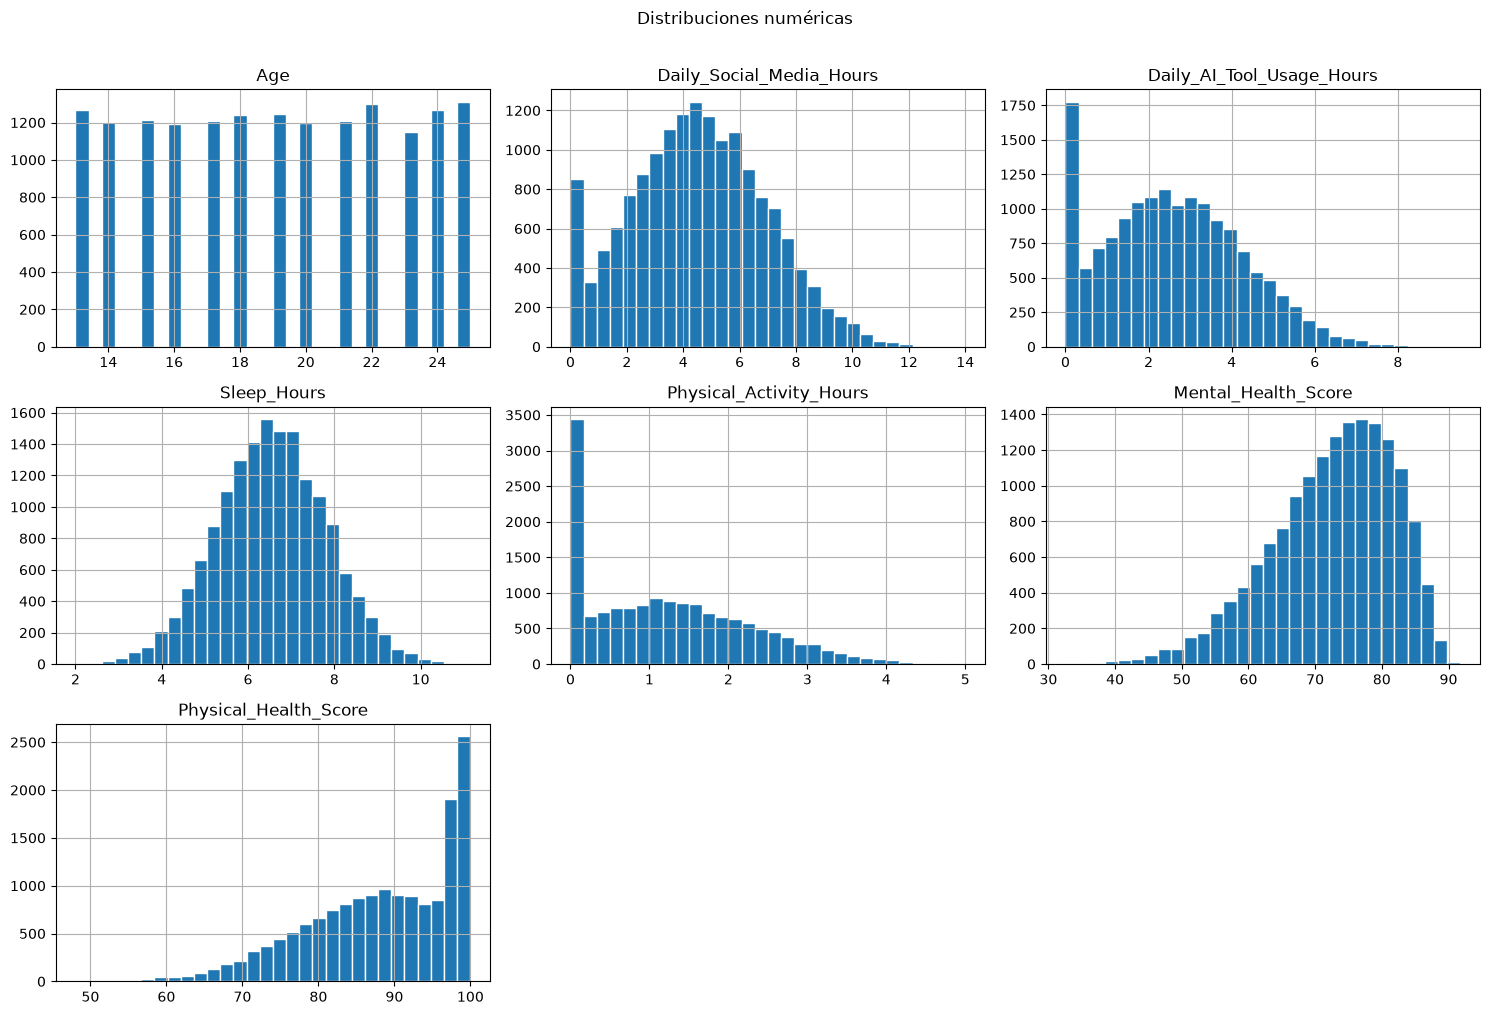

Porcentajes de Student_ID:


,porcentaje
Student_ID,
STU_00001,0.01
STU_00002,0.01
STU_00003,0.01
STU_00004,0.01
STU_00005,0.01
...,...
STU_15996,0.01
STU_15997,0.01
STU_15998,0.01


Porcentajes de Gender:


,porcentaje
Gender,
Male,48.40
Female,47.68
Non-binary,3.92


Porcentajes de Education_Level:


,porcentaje
Education_Level,
High School,38.02
University,31.42
College,30.56


In [13]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x=TARGET, kde=True, ax=ax[0], color="teal")
ax[0].set_title("Distribución del objetivo")
sns.boxplot(data=df, x=TARGET, ax=ax[1], color="lightseagreen")
ax[1].set_title("Resumen del objetivo")
plt.tight_layout()
plt.show()

df[numeric_columns].hist(figsize=(15, 10), bins=30, edgecolor="white")
plt.suptitle("Distribuciones numéricas", y=1.01)
plt.tight_layout()
plt.show()
for col in categorical_columns:
    print(f"Porcentajes de {col}:")
    display((100 * df[col].value_counts(normalize=True, dropna=False))
            .round(2).rename("porcentaje").to_frame())

## 5.3 Calidad y preparación

Se revisan nulos, duplicados, identificadores duplicados, tipos, categorías, rangos y posibles valores atípicos con la regla exploratoria de 1.5×IQR. Una observación marcada por IQR no es necesariamente errónea: como no hay límites de dominio documentados, no se elimina ni recorta automáticamente. Los rangos empíricos no son límites clínicos.

In [14]:
print("Faltantes por columna:")
display(df.isna().sum().rename("faltantes").to_frame())
print("Filas duplicadas completas:", int(df.duplicated().sum()))
if "Student_ID" in df:
    print("Student_ID duplicados:", int(df["Student_ID"].duplicated().sum()))
print("Tipos:")
display(df.dtypes.rename("tipo").to_frame())
for col in categorical_columns:
    print(f"{col}: {sorted(df[col].dropna().astype(str).unique().tolist())}")
print("Rangos observados (no límites validados):")
display(pd.DataFrame({"mínimo": df[numeric_columns].min(),
                      "máximo": df[numeric_columns].max()}))

rows = []
for col in numeric_columns:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variable": col, "límite_inf": low, "límite_sup": high,
                 "casos_IQR": int(((df[col] < low) | (df[col] > high)).sum())})
display(pd.DataFrame(rows).set_index("variable").round(2))

Faltantes por columna:


,faltantes
Student_ID,0
Age,0
Gender,0
Education_Level,0
Daily_Social_Media_Hours,0
Daily_AI_Tool_Usage_Hours,0
Sleep_Hours,0
Physical_Activity_Hours,0
Mental_Health_Score,0
Physical_Health_Score,0


Filas duplicadas completas: 0
Student_ID duplicados: 0
Tipos:


,tipo
Student_ID,str
Age,int64
Gender,str
Education_Level,str
Daily_Social_Media_Hours,float64
Daily_AI_Tool_Usage_Hours,float64
Sleep_Hours,float64
Physical_Activity_Hours,float64
Mental_Health_Score,float64
Physical_Health_Score,float64


Student_ID: ['STU_00001', 'STU_00002', 'STU_00003', 'STU_00004', 'STU_00005', 'STU_00006', 'STU_00007', 'STU_00008', 'STU_00009', 'STU_00010', 'STU_00011', 'STU_00012', 'STU_00013', 'STU_00014', 'STU_00015', 'STU_00016', 'STU_00017', 'STU_00018', 'STU_00019', 'STU_00020', 'STU_00021', 'STU_00022', 'STU_00023', 'STU_00024', 'STU_00025', 'STU_00026', 'STU_00027', 'STU_00028', 'STU_00029', 'STU_00030', 'STU_00031', 'STU_00032', 'STU_00033', 'STU_00034', 'STU_00035', 'STU_00036', 'STU_00037', 'STU_00038', 'STU_00039', 'STU_00040', 'STU_00041', 'STU_00042', 'STU_00043', 'STU_00044', 'STU_00045', 'STU_00046', 'STU_00047', 'STU_00048', 'STU_00049', 'STU_00050', 'STU_00051', 'STU_00052', 'STU_00053', 'STU_00054', 'STU_00055', 'STU_00056', 'STU_00057', 'STU_00058', 'STU_00059', 'STU_00060', 'STU_00061', 'STU_00062', 'STU_00063', 'STU_00064', 'STU_00065', 'STU_00066', 'STU_00067', 'STU_00068', 'STU_00069', 'STU_00070', 'STU_00071', 'STU_00072', 'STU_00073', 'STU_00074', 'STU_00075', 'STU_00076',

,mínimo,máximo
Age,13.00,25.00
Daily_Social_Media_Hours,0.00,14.00
Daily_AI_Tool_Usage_Hours,0.00,9.50
Sleep_Hours,2.00,11.15
Physical_Activity_Hours,0.00,5.00
Mental_Health_Score,32.56,91.76
Physical_Health_Score,48.03,99.98


,límite_inf,límite_sup,casos_IQR
variable,,,
Age,7.00,31.00,0
Daily_Social_Media_Hours,-2.17,11.19,49
Daily_AI_Tool_Usage_Hours,-2.35,7.41,51
Sleep_Hours,3.08,10.01,105
Physical_Activity_Hours,-2.16,4.43,55
Mental_Health_Score,47.58,98.73,185
Physical_Health_Score,58.04,120.65,63


**Preparación:** si la inspección confirma que no hay faltantes, no se requiere imputación en los datos actuales; se mantiene imputación mediana/moda dentro del pipeline para robustez. Se excluye el ID. Se conservan valores extremos plausibles. One-hot codifica categóricas y `StandardScaler` escala numéricas; el preprocesamiento se ajusta dentro de cada pliegue para evitar fuga. El escalamiento es importante para modelos lineales y no perjudica la comparación con árboles.

## 5.4 Formulación de X e y

`y = Mental_Health_Score`. `X` contiene edad, género, educación, horas de redes sociales y de IA, sueño, actividad física y salud física. Se excluye `Student_ID` por ser identificador y no aportar una característica generalizable.

`Physical_Health_Score` se incluye bajo el supuesto de que está disponible al momento de predecir. Puede ser un proxy correlacionado; no hay documentación de cuándo se midió ni de cómo se generaron los puntajes. Si no está disponible en producción o se deriva del objetivo, debe excluirse y reentrenar. No se identifican variables derivadas directamente del objetivo. Como `y` es continua, se trata de regresión supervisada y no de clustering.

In [15]:
from sklearn.model_selection import train_test_split

feature_names = [
    "Age", "Gender", "Education_Level",
    "Daily_Social_Media_Hours", "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours", "Physical_Activity_Hours", "Physical_Health_Score",
]
missing = sorted(set(feature_names + [TARGET]) - set(df.columns))
if missing:
    raise ValueError(f"Faltan columnas requeridas: {missing}")
X, y = df[feature_names].copy(), df[TARGET].copy()
if not pd.api.types.is_numeric_dtype(y):
    raise TypeError(f"{TARGET} debe ser numérico para regresión.")
if X.isna().any().any() or y.isna().any():
    raise ValueError("Resolver los valores faltantes antes de entrenar.")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=SEED
)
print("Predictoras:", feature_names)
print("Objetivo:", TARGET)
print("Entrenamiento:", X_train.shape, "| Test reservado:", X_test.shape)
print("Test no participa en CV, selección ni ajuste.")

Predictoras: ['Age', 'Gender', 'Education_Level', 'Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours', 'Sleep_Hours', 'Physical_Activity_Hours', 'Physical_Health_Score']
Objetivo: Mental_Health_Score
Entrenamiento: (12800, 8) | Test reservado: (3200, 8)
Test no participa en CV, selección ni ajuste.


## 5.5 División y estrategia de validación

La partición 80/20 deja suficientes casos para entrenamiento y validación y reserva un Test amplio dado el tamaño de la muestra. No se estratifica porque el objetivo es continuo. Se aplica `KFold` de cinco pliegues, barajado con semilla fija, únicamente al 80% de entrenamiento. Se comparan media y desviación estándar de MAE, RMSE y R² entre pliegues. Test se usa una sola vez tras elegir el modelo.

## 5.6 Entrenamiento y comparación

Se comparan cuatro enfoques: regresión lineal (referencia interpretable), Ridge (regularización L2), Random Forest (ensamble de árboles y relaciones no lineales) e HistGradientBoosting (boosting de árboles). Los hiperparámetros se fijan antes de consultar Test; no se realiza búsqueda sobre Test. El pipeline coloca imputación, codificación y escalamiento dentro de cada pliegue, evitando ajustar transformaciones con datos de validación.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
model_configs = {
    "LinearRegression": LinearRegression(),
    "Ridge_alpha_10": Ridge(alpha=10.0),
    "RandomForest_300": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=1.0,
        random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=.08, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=SEED),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"mae": "neg_mean_absolute_error",
           "rmse": "neg_root_mean_squared_error", "r2": "r2"}
pipelines, records = {}, []
for name, estimator in model_configs.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    score = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                           n_jobs=-1, error_score="raise")
    pipelines[name] = pipe
    records.append({
        "modelo": name,
        "MAE medio": -score["test_mae"].mean(),
        "MAE DE": score["test_mae"].std(ddof=1),
        "RMSE medio": -score["test_rmse"].mean(),
        "RMSE DE": score["test_rmse"].std(ddof=1),
        "R2 medio": score["test_r2"].mean(),
        "R2 DE": score["test_r2"].std(ddof=1),
    })
cv_results = pd.DataFrame(records).sort_values("RMSE medio").reset_index(drop=True)
display(cv_results.round(4))

,modelo,MAE medio,MAE DE,RMSE medio,RMSE DE,R2 medio,R2 DE
0,RandomForest_300,6.2726,0.0913,8.0133,0.1056,0.2503,0.0206
1,Ridge_alpha_10,6.3806,0.0748,8.0425,0.1040,0.2450,0.0106
2,LinearRegression,6.3806,0.0748,8.0426,0.1040,0.2450,0.0106
3,HistGradientBoosting,6.3950,0.0917,8.0654,0.1159,0.2406,0.0148


## 5.7 Evaluación e interpretación

MAE es el error absoluto promedio en puntos del puntaje; RMSE está en las mismas unidades y penaliza más los errores grandes; R² compara con predecir la media y puede ser negativo fuera de muestra. Para el modelo elegido se informan matriz de dispersión observado/predicho y residuos en Test. Accuracy, precision, recall, F1 y ROC-AUC son métricas de clasificación y no aplican a este objetivo continuo. Las métricas no representan validez clínica.

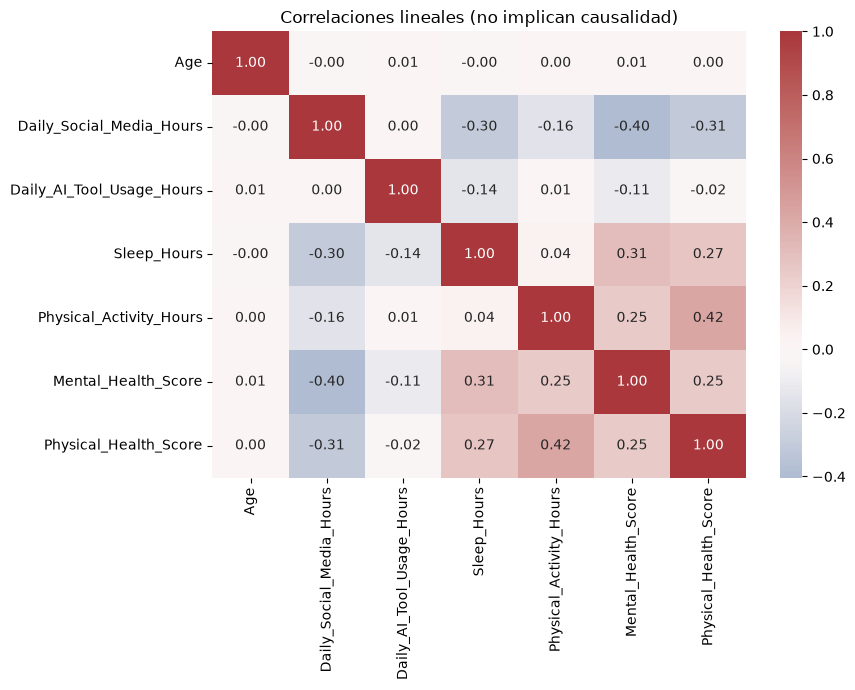

Elegido solo por menor RMSE medio en CV: RandomForest_300
Evaluación final única en Test:


,valor
MAE,6.1341
RMSE,7.8773
R2,0.2645


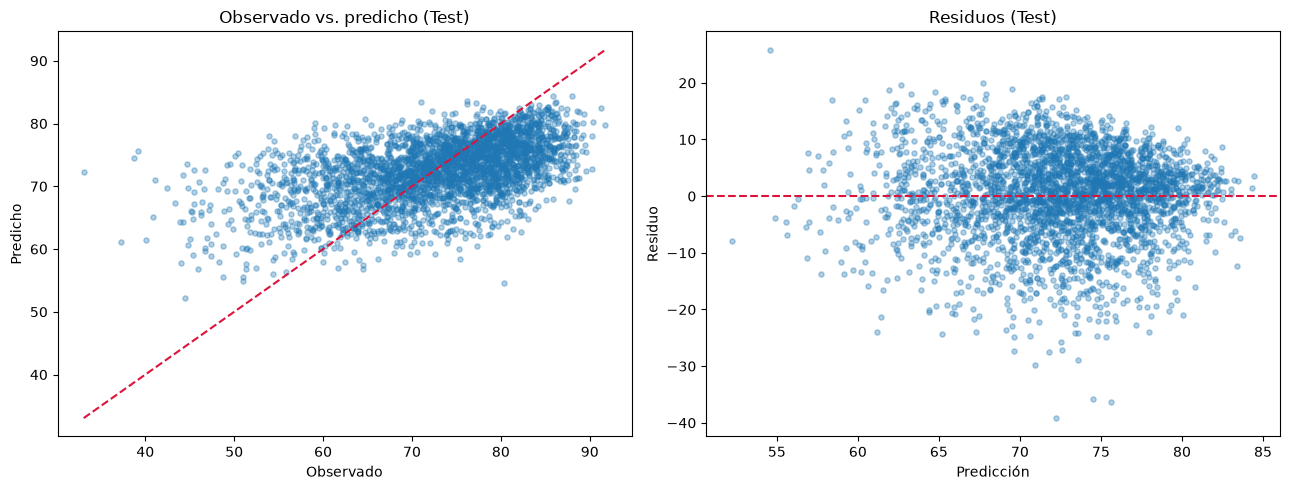

In [17]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="vlag",
            center=0, annot=True, fmt=".2f")
plt.title("Correlaciones lineales (no implican causalidad)")
plt.tight_layout()
plt.show()

selected_name = cv_results.loc[0, "modelo"]
selected_pipeline = pipelines[selected_name]
print("Elegido solo por menor RMSE medio en CV:", selected_name)
selected_pipeline.fit(X_train, y_train)
test_predictions = selected_pipeline.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
test_metrics = {
    "MAE": mean_absolute_error(y_test, test_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "R2": r2_score(y_test, test_predictions),
}
print("Evaluación final única en Test:")
display(pd.Series(test_metrics, name="valor").to_frame().round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, test_predictions, alpha=.35, s=14)
lims = [min(y_test.min(), test_predictions.min()),
        max(y_test.max(), test_predictions.max())]
ax[0].plot(lims, lims, "--", color="crimson")
ax[0].set(xlabel="Observado", ylabel="Predicho", title="Observado vs. predicho (Test)")
residuals = y_test.to_numpy() - test_predictions
ax[1].scatter(test_predictions, residuals, alpha=.35, s=14)
ax[1].axhline(0, linestyle="--", color="crimson")
ax[1].set(xlabel="Predicción", ylabel="Residuo", title="Residuos (Test)")
plt.tight_layout()
plt.show()

El modelo se selecciona exclusivamente con CV. La desviación estándar entre pliegues aproxima estabilidad; MAE y R² son criterios complementarios de interpretación. La evaluación Test estima generalización y no autoriza volver a escoger modelos o ajustar parámetros. Si el rendimiento no sirve al propósito previsto, hacen falta datos mejor documentados o representativos; no se reajusta a partir de Test.

## 5.8 Selección y ajuste

La alternativa final es la de menor RMSE promedio en los cinco pliegues de entrenamiento. Se reportan también variabilidad, MAE, R² y sus desviaciones. Se favorece un balance entre desempeño, estabilidad, interpretabilidad y costo: hay una referencia lineal y tres algoritmos de árboles con complejidad acotada. No se usa Test para selección ni ajuste; no se hizo búsqueda posterior de hiperparámetros.

In [18]:
print("Resultados CV de la alternativa elegida:")
display(cv_results.iloc[0].to_frame("valor"))
print("Parámetros:")
display(pd.Series(model_configs[selected_name].get_params()).to_frame("valor"))

Resultados CV de la alternativa elegida:


,valor
modelo,RandomForest_300
MAE medio,6.27261
MAE DE,0.091286
RMSE medio,8.013321
RMSE DE,0.105601
R2 medio,0.250276
R2 DE,0.020571


Parámetros:


,valor
bootstrap,True
ccp_alpha,0.0
criterion,squared_error
max_depth,None
max_features,1.0
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0
min_samples_leaf,2
min_samples_split,2


## 5.9 Registro del modelo con MLflow

Se registra un experimento con métricas de validación cruzada para todos los candidatos y una tabla comparativa; únicamente se registra en Model Registry el pipeline elegido por menor RMSE medio en CV. La base SQLite y los artefactos se guardan junto al Excel, independientemente del directorio de trabajo. Se fija el formato cloudpickle porque el formato skops predeterminado de MLflow puede rechazar tipos del pipeline; cargar únicamente modelos propios y confiables. Para persistir y recuperar la información, la interfaz de MLflow debe iniciarse usando esa misma base en `03_Notebook\mlflow.db`.

In [19]:
import json
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

EXPERIMENT_NAME = "proyecto_final_salud_estudiantil"
REGISTERED_MODEL_NAME = "MentalHealthScoreModel"
working_dirs = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
NOTEBOOK_DIR = next(
    (path for path in working_dirs
     if path.name == "03_Notebook" and (path / "proyecto_final.ipynb").is_file()),
    None,
)
if NOTEBOOK_DIR is None:
    NOTEBOOK_DIR = next(
        (path / "03_Notebook" for path in working_dirs
         if (path / "03_Notebook" / "proyecto_final.ipynb").is_file()),
        None,
    )
if NOTEBOOK_DIR is None:
    raise FileNotFoundError("No se encontró la carpeta 03_Notebook del proyecto.")
TRACKING_DB = NOTEBOOK_DIR / "mlflow.db"
ARTIFACT_ROOT = NOTEBOOK_DIR / "mlruns"
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{TRACKING_DB.resolve().as_posix()}")
client = MlflowClient()
if client.get_experiment_by_name(EXPERIMENT_NAME) is None:
    client.create_experiment(
        EXPERIMENT_NAME, artifact_location=ARTIFACT_ROOT.resolve().as_uri()
    )
mlflow.set_experiment(EXPERIMENT_NAME)
example = X_train.head(3)
signature = infer_signature(example, selected_pipeline.predict(example))
with mlflow.start_run(run_name=selected_name) as run:
    run_id = run.info.run_id
    mlflow.log_param("selected_model", selected_name)
    mlflow.log_param("target", TARGET)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("test_size", .20)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("features", json.dumps(feature_names))
    for key, value in model_configs[selected_name].get_params(deep=False).items():
        if isinstance(value, (str, int, float, bool)) or value is None:
            mlflow.log_param(f"model.{key}", "None" if value is None else value)
    for _, row in cv_results.iterrows():
        prefix = row["modelo"].replace(".", "_")
        for metric in ["MAE medio", "MAE DE", "RMSE medio", "RMSE DE",
                       "R2 medio", "R2 DE"]:
            key = metric.replace(" ", "_")
            mlflow.log_metric(f"cv.{prefix}.{key}", float(row[metric]))
    for key, value in test_metrics.items():
        mlflow.log_metric(f"test.{key.lower()}", float(value))
    mlflow.log_table(cv_results, artifact_file="cv_comparison.json")
    mlflow.log_dict({
        "target": TARGET,
        "features": feature_names,
        "excluded": {"Student_ID": "identificador no generalizable"},
        "selection_rule": "menor RMSE medio en CV de 5 pliegues",
        "test_role": "evaluación final única",
        "data_file": DATA_FILENAME,
    }, "model_card.json")
    mlflow.sklearn.log_model(
        sk_model=selected_pipeline, name="model",
        registered_model_name=REGISTERED_MODEL_NAME,
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
        signature=signature, input_example=example,
    )
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
matching = [v for v in versions if v.run_id == run_id]
if not matching:
    raise RuntimeError("No se encontró la versión del modelo registrado en MLflow.")
registered_version = max(matching, key=lambda v: int(v.version))
MODEL_URI = f"models:/{REGISTERED_MODEL_NAME}/{registered_version.version}"
print("Experimento:", EXPERIMENT_NAME)
print("Run ID:", run_id)
print("Versión:", registered_version.version)
print("URI:", MODEL_URI)

c:\Users\USER\Documents\PROYECTO _FINAL_MULTIVALUADO\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/17 18:30:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which

Experimento: proyecto_final_salud_estudiantil
Run ID: 78564a169df94a0eb712c7c689ece1b3
Versión: 1
URI: models:/MentalHealthScoreModel/1


Successfully registered model 'MentalHealthScoreModel'.
Created version '1' of model 'MentalHealthScoreModel'.


## 5.10 Uso posterior: recuperación e inferencia

Se recupera el pipeline registrado (incluye imputación, escalamiento y codificación) y se predicen dos registros ficticios. La entrada debe conservar exactamente las columnas y significados usados al entrenar, salvo ID y objetivo. Las categorías desconocidas se procesan con `handle_unknown="ignore"`; esto no garantiza que la predicción sea fiable fuera de la distribución observada.

In [20]:
loaded_model = mlflow.sklearn.load_model(MODEL_URI)
new_students = pd.DataFrame([
    {"Age": 19, "Gender": "Female", "Education_Level": "University",
     "Daily_Social_Media_Hours": 4.0, "Daily_AI_Tool_Usage_Hours": 2.0,
     "Sleep_Hours": 7.0, "Physical_Activity_Hours": 1.0,
     "Physical_Health_Score": 85.0},
    {"Age": 17, "Gender": "Non-binary", "Education_Level": "High School",
     "Daily_Social_Media_Hours": 6.0, "Daily_AI_Tool_Usage_Hours": 3.0,
     "Sleep_Hours": 6.0, "Physical_Activity_Hours": .5,
     "Physical_Health_Score": 78.0},
], columns=feature_names)
if list(new_students.columns) != feature_names:
    raise ValueError(f"Esquema esperado: {feature_names}")
if new_students.isna().any().any():
    warnings.warn("La entrada tiene faltantes; se aplicarán imputadores entrenados.")
predictions = loaded_model.predict(new_students)
results = new_students.copy()
results[f"Predicted_{TARGET}"] = predictions
display(results)

,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Physical_Health_Score,Predicted_Mental_Health_Score
0,19,Female,University,4.0,2.0,7.0,1.0,85.0,73.631004
1,17,Non-binary,High School,6.0,3.0,6.0,0.5,78.0,67.506538


## Conclusiones y limitaciones

- Los resultados solo describen el archivo local; representatividad, temporalidad y escalas no están documentadas.
- Las asociaciones no son causales; una predicción de puntaje no es diagnóstico ni recomendación.
- El modelo depende de que todos los predictores —en especial `Physical_Health_Score`— existan en el uso real.
- Validar con datos nuevos y representativos antes de cualquier despliegue, en particular para decisiones de alto impacto.
- Para reproducir, conservar `mlflow.db`, los artefactos locales, el Excel y las versiones de Python y librerías.